## Robust Scaling

Robust Scaling is a feature scaling technique that uses the **median** and **interquartile range (IQR)** to scale numerical features. It is less affected by outliers than Standardization because the median and IQR are less sensitive to extreme values than the mean and standard deviation.

**Formula:**

$$
X' = \frac{X - Q_2}{Q_3 - Q_1}
$$

Where:
- \(X\) = Original feature value
- \(Q_2\) = Median (50th percentile)
- \(Q_1\) = First quartile (25th percentile)
- \(Q_3\) = Third quartile (75th percentile)
- \(IQR = Q_3 - Q_1\)

**Usage:**
- Particularly useful for numerical datasets containing outliers, especially when using scale-sensitive ML algorithms such as KNN, K-Means, and SVM.

**Key Observations:**
- The median of each scaled feature becomes approximately 0.
- The IQR of each scaled feature becomes approximately 1.
- It is less affected by extreme values than Standardization and Min-Max Scaling.
- It does **not remove outliers**; outlier observations remain in the dataset.
- It does not restrict values to a fixed range, so scaled values can still be very large or very small.
- It is useful when you want to scale features without allowing extreme values to strongly influence the scaling parameters.

In [37]:
#IMPORTING BASIC LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [38]:
data=pd.read_csv(r'D:\programming\datasets\weather_classification_data.csv')
data.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy


In [39]:
#Let us use only 2 numerical features and our one categorical feature - weather type
df=pd.read_csv(r'D:\programming\datasets\weather_classification_data.csv',usecols=['Temperature' , 'Humidity', 'Weather Type'])
df.head()

,Temperature,Humidity,Weather Type
0,14.0,73,Rainy
1,39.0,96,Cloudy
2,30.0,64,Sunny
3,38.0,83,Sunny
4,27.0,74,Rainy


In [40]:
df.info() #gives us info upon non null and data types of columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Temperature   13200 non-null  float64
 1   Humidity      13200 non-null  int64  
 2   Weather Type  13200 non-null  object 
dtypes: float64(1), int64(1), object(1)
memory usage: 309.5+ KB


In [41]:
df.shape

(13200, 3)

In [42]:
df.duplicated().sum() #checks if any duplicates 

np.int64(7648)

In [43]:
df.drop_duplicates(inplace=True)

In [44]:
df.shape #shape of dataset changed after dropping of duplicate values.

(5552, 3)

<Axes: xlabel='Temperature', ylabel='Humidity'>

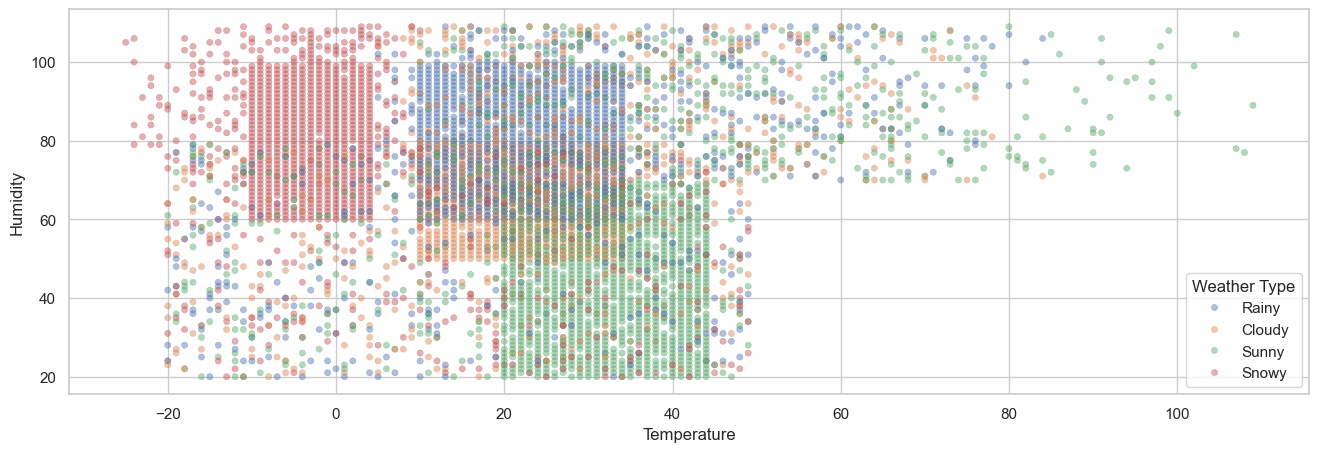

In [45]:
#scatter plot
sns.set_theme(style='whitegrid')
plt.figure(figsize=(16,5))
sns.scatterplot(data=df,x='Temperature',y='Humidity',hue='Weather Type' , s=20 , alpha=0.45,edgecolor=None)


<Axes: xlabel='Weather Type', ylabel='Humidity'>

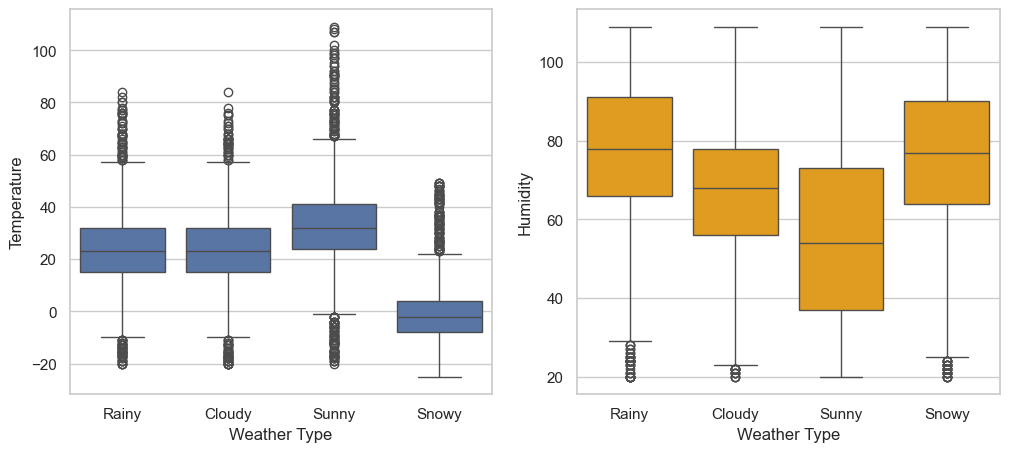

In [46]:
#box plot to determine outliers
fig , (ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
sns.boxplot(data=df, x='Weather Type' , y='Temperature',ax=ax1)
sns.boxplot(data=df,x='Weather Type' , y='Humidity',ax=ax2,color='orange')

#We can see the huge amont of outliers.

**Defining our variables X and y**

In [47]:
X=df.drop(columns=['Weather Type'])
y=df['Weather Type']

## TRAIN_TEST_SPLIT ##

In [48]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.3 , random_state=36)

X_train

,Temperature,Humidity
3481,28.0,65
5095,41.0,75
7907,2.0,56
8357,52.0,75
434,39.0,94
...,...,...
1459,36.0,47
4393,14.0,91
1013,22.0,67
653,27.0,21


## ROBUST SCALING ##

In [49]:
from sklearn.preprocessing import RobustScaler

scalar=RobustScaler()

X_train_scaled=scalar.fit_transform(X_train)
X_test_scaled=scalar.transform(X_test)

In [50]:
X_train_scaled #its a numpy matrix

array([[ 0.16666667, -0.12121212],
       [ 0.70833333,  0.18181818],
       [-0.91666667, -0.39393939],
       ...,
       [-0.08333333, -0.06060606],
       [ 0.125     , -1.45454545],
       [ 0.83333333, -0.6969697 ]], shape=(3886, 2))

In [51]:
#conversion from matrix to dataframe
X_train_scaled = pd.DataFrame(X_train_scaled, columns=['Temperature', 'Humidity'], index=X_train.index)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=['Temperature', 'Humidity'], index=X_test.index)

In [52]:
X_train_scaled #its a pandas Dataframe now

,Temperature,Humidity
3481,0.166667,-0.121212
5095,0.708333,0.181818
7907,-0.916667,-0.393939
8357,1.166667,0.181818
434,0.625000,0.757576
...,...,...
1459,0.500000,-0.666667
4393,-0.416667,0.666667
1013,-0.083333,-0.060606
653,0.125000,-1.454545


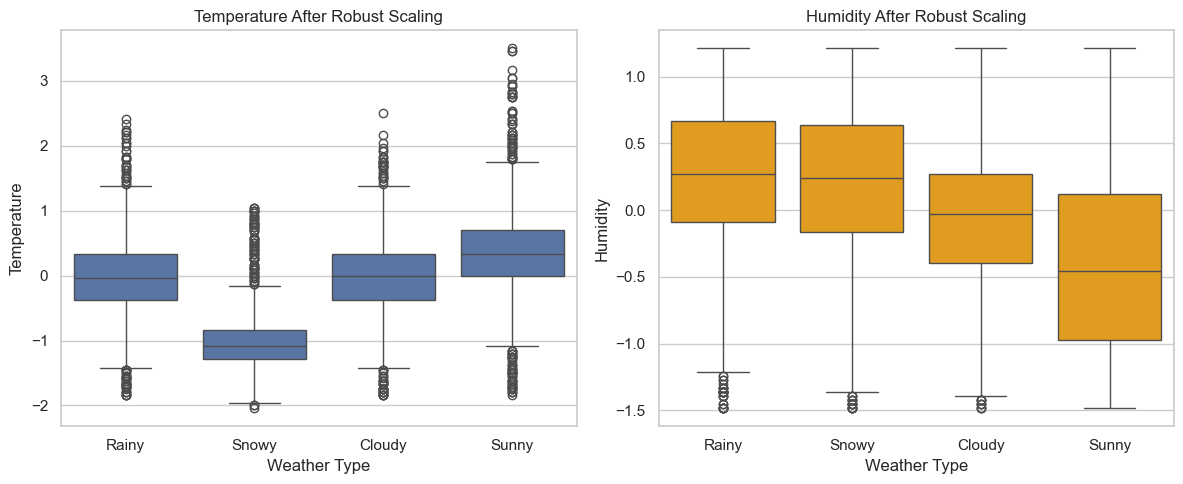

In [53]:
#Will check if any outliers present now by boxplot
X_train_scaled['Weather Type'] = y_train

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

sns.boxplot(data=X_train_scaled, x='Weather Type', y='Temperature', ax=ax1)
ax1.set_title('Temperature After Robust Scaling')

sns.boxplot(data=X_train_scaled, x='Weather Type', y='Humidity', ax=ax2, color='orange')
ax2.set_title('Humidity After Robust Scaling')

plt.tight_layout()
plt.show()

#We can see the huge amont of outliers but now as scaled wont affect much.